# Nama : Chika Putri Fajarini
# Projek Citra Biomedik
# **Studi Kasus : Retina Detection**

## **Library**

**Install library**

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 19.8 MB/s eta 0:00:00


**Import library**

In [ ]:
import os
import cv2
import pandas as pd
import numpy as np
import seaborn as sns
import albumentations as A
import torch
import shutil
import random
from tqdm import tqdm
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


**Load dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

IMAGE_DIR = Path(r"/content/drive/MyDrive/retina_2class/images")
LABEL_DIR = Path(r"/content/drive/MyDrive/retina_2class/labels")

def load_yolo_label(label_path):
    boxes = []
    classes = []
    if not os.path.exists(label_path):
        return boxes, classes  # label kosong / tidak ada
    with open(label_path, "r") as f:
        for line in f.readlines():
            parts = line.strip().split()
            cls = int(parts[0])
            bbox = list(map(float, parts[1:]))
            classes.append(cls)
            boxes.append(bbox)
    return boxes, classes

**Membaca dataset**

In [ ]:
rows = []
for img_name in sorted(os.listdir(IMAGE_DIR)):
    img_path = os.path.join(IMAGE_DIR, img_name)
    base = os.path.splitext(img_name)[0]
    label_path = os.path.join(LABEL_DIR, f"{base}.txt")
    if not os.path.exists(img_path):
        print("Image tidak ditemukan:", img_path)
        continue
    img = cv2.imread(img_path)
    boxes, classes = load_yolo_label(label_path)
    row = {
        "image_name": img_name,
        "image_path": img_path,
        "label_path": label_path,
        "num_boxes": len(boxes),
        "classes": classes,
        "boxes": boxes
    }
    rows.append(row)
# Convert ke DataFrame
df = pd.DataFrame(rows)
df

,image_name,image_path,label_path,num_boxes,classes,boxes
0,00cc2b75cddd_png_jpg.rf.dbdfed04f62c99ec8903a4...,/content/drive/MyDrive/retina_2class/images/00...,/content/drive/MyDrive/retina_2class/labels/00...,2,"[0, 1]","[[0.65625, 0.51953125, 0.078125, 0.095703125],..."
1,0a4e1a29ffff_png_jpg.rf.b9cb31c4a6d06e7f495fb1...,/content/drive/MyDrive/retina_2class/images/0a...,/content/drive/MyDrive/retina_2class/labels/0a...,2,"[1, 0]","[[0.8125, 0.392578125, 0.16015625, 0.185546875..."
2,0a902c80d5da_png_jpg.rf.0e4023b1674cf002500cb9...,/content/drive/MyDrive/retina_2class/images/0a...,/content/drive/MyDrive/retina_2class/labels/0a...,2,"[0, 1]","[[0.49609375, 0.623046875, 0.083984375, 0.0917..."
3,0ada12c0e78f_png_jpg.rf.8ae2354b2bf7109e8a33b5...,/content/drive/MyDrive/retina_2class/images/0a...,/content/drive/MyDrive/retina_2class/labels/0a...,2,"[0, 1]","[[0.48046875, 0.5078125, 0.111328125, 0.144531..."
4,0ae2dd2e09ea_png_jpg.rf.2c720a558928f4044fc4f0...,/content/drive/MyDrive/retina_2class/images/0a...,/content/drive/MyDrive/retina_2class/labels/0a...,2,"[1, 0]","[[0.76953125, 0.5, 0.171875, 0.193359375], [0...."
5,0b00f8a77510_png_jpg.rf.f2f142e801baf06effb5a8...,/content/drive/MyDrive/retina_2class/images/0b...,/content/drive/MyDrive/retina_2class/labels/0b...,2,"[1, 0]","[[0.8046875, 0.482421875, 0.154296875, 0.24609..."
6,0babc12807b2_png_jpg.rf.75c24fbb7e187a5f3f1afb...,/content/drive/MyDrive/retina_2class/images/0b...,/content/drive/MyDrive/retina_2class/labels/0b...,2,"[0, 1]","[[0.47265625, 0.462890625, 0.109375, 0.1640625..."
7,0babc12807b2_png_jpg.rf.8f39e273b03ebecb4f37b8...,/content/drive/MyDrive/retina_2class/images/0b...,/content/drive/MyDrive/retina_2class/labels/0b...,2,"[0, 1]","[[0.462890625, 0.47265625, 0.150390625, 0.1875..."
8,0bf37ca3156a_png_jpg.rf.7ff0d9aea9ae18008da7a1...,/content/drive/MyDrive/retina_2class/images/0b...,/content/drive/MyDrive/retina_2class/labels/0b...,2,"[1, 0]","[[0.1875, 0.5234375, 0.138671875, 0.19921875],..."
9,0c38940e1f80_png_jpg.rf.3f43dccc202d7aff7b6394...,/content/drive/MyDrive/retina_2class/images/0c...,/content/drive/MyDrive/retina_2class/labels/0c...,2,"[1, 0]","[[0.640625, 0.642578125, 0.181640625, 0.203125..."


**Terdiri dari 2 class :**
1. macular
2. optical_disk

## **Augmentasi**

In [ ]:
AUG_IMG_DIR = Path(r"Augmentasi_images")
AUG_LABEL_DIR = Path(r"Augmentasi_labels")
AUG_IMG_DIR.mkdir(parents=True, exist_ok=True)
AUG_LABEL_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
def load_yolo_label(label_path: Path):
    boxes, classes = [], []
    if not label_path.exists():
        return boxes, classes
    with open(label_path, "r") as f:
        for ln in f:
            parts = ln.strip().split()
            if len(parts) < 5:
                continue
            try:
                cls = int(parts[0])
                bbox = list(map(float, parts[1:5]))  # x_center y_center w h (YOLO)
            except:
                continue
            classes.append(cls)
            boxes.append(bbox)
    return boxes, classes

def save_yolo_label(save_path: Path, classes, boxes):
    with open(save_path, "w") as f:
        for cls, box in zip(classes, boxes):
            # round untuk konsistensi (bisa dihapus jika ingin lebih presisi)
            box_str = " ".join(f"{v:.6f}" for v in box)
            f.write(f"{cls} {box_str}\n")

In [ ]:
import random

_pipelines = [] # Global variable to store pipelines

def make_pipelines():
    """Initializes and returns a list of Albumentations pipelines."""
    pipelines = []
    # pipeline 1: brightness / hue + flip / rotate
    pipelines.append(A.Compose([
        A.RandomBrightnessContrast(p=0.9),
        A.HueSaturationValue(p=0.7),
        A.HorizontalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.12, rotate_limit=15, p=0.6),
        A.GaussNoise(var_limit=(10.0, 50.0), p=0.4),
        A.MotionBlur(blur_limit=3, p=0.3),
    ], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'])))
    # Add more pipelines here if needed
    return pipelines

# Call make_pipelines to initialize _pipelines
_pipelines = make_pipelines()

def augment_image(img, boxes, classes, num_attempts=5):
    """
    Applies augmentation to an image and its bounding boxes/classes using a random pipeline.
    Tries several times if no valid bounding boxes remain after augmentation.
    """
    for _ in range(num_attempts):
        if not _pipelines:
            print("No augmentation pipelines defined. Returning original image.")
            return img, boxes, classes

        # Randomly choose one pipeline if multiple are defined
        pipeline = random.choice(_pipelines)

        # Albumentations expects boxes as a list of lists/tuples, and classes as a list
        # It's important that classes are passed via label_fields for bbox_params
        transformed = pipeline(image=img, bboxes=boxes, class_labels=classes)

        aug_img = transformed['image']
        aug_boxes = transformed['bboxes']
        aug_classes = transformed['class_labels']

        # Ensure that at least one bounding box remains after augmentation
        if len(aug_boxes) > 0:
            return aug_img, aug_boxes, aug_classes
    print(f"Warning: Failed to augment image and preserve bounding boxes after {num_attempts} attempts.")
    return None, None, None # Return None if no successful augmentation after attempts

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipython-input-1675623274.py:14: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.4),


In [ ]:
import uuid

target_total = 100
current_total = 0
aug_idx = 0

# Ambil daftar file gambar (ekstensi umum)
image_files = sorted([p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]])

if len(image_files) == 0:
    raise ValueError("Tidak ada gambar di IMAGE_DIR. Periksa path IMAGE_DIR.")

# supaya variasi: shuffle list tiap epoch
with tqdm(total=target_total, desc="Augmenting") as pbar:
    while current_total < target_total:
        random.shuffle(image_files)
        for img_path in image_files:
            if current_total >= target_total:
                break
            base = img_path.stem
            label_path = LABEL_DIR / f"{base}.txt"
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            boxes, classes = load_yolo_label(label_path);
            if len(boxes) == 0:
                # opsional: bisa augmentasi background-only images juga, tapi saat ini skip
                continue

            aug_img, aug_boxes, aug_classes = augment_image(img, boxes, classes)
            if aug_img is None:
                # skip jika transform merusak bbox pada semua percobaan
                continue

            # nama file unik -> base_augUUID.jpg agar tidak mudah mirip
            unique = uuid.uuid4().hex[:8]
            new_image_name = f"{base}_aug_{unique}.jpg"
            new_label_name = f"{base}_aug_{unique}.txt"

            # simpan image (jpg) dan label
            save_path_img = AUG_IMG_DIR / new_image_name
            save_path_label = AUG_LABEL_DIR / new_label_name

            # simpan dengan kualitas JPEG 95 untuk mempertahankan detail
            cv2.imwrite(str(save_path_img), aug_img, [int(cv2.IMWRITE_JPEG_QUALITY), 95])
            save_yolo_label(save_path_label, aug_classes, aug_boxes)

            current_total += 1
            aug_idx += 1
            pbar.update(1)

print("Augmentasi selesai")
print("Total image augmented:", current_total)

Augmenting: 100%|██████████| 100/100 [00:01<00:00, 85.07it/s]

Augmentasi selesai
Total image augmented: 100


## **Enhancement**

In [ ]:
# -------------------------
# Enhancement functions
# -------------------------
def enhance_image_cv(img: np.ndarray) -> np.ndarray:
    """Enhance using CLAHE + unsharp mask. Input BGR, return BGR."""
    # convert to LAB for CLAHE on L channel
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    l_clahe = clahe.apply(l)
    lab_clahe = cv2.merge((l_clahe, a, b))
    img_clahe = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2BGR)

    # Unsharp mask
    blur = cv2.GaussianBlur(img_clahe, (0,0), sigmaX=3)
    unsharp = cv2.addWeighted(img_clahe, 1.5, blur, -0.5, 0)
    return unsharp

def batch_enhance(src_img_dir: Path, dst_img_dir: Path):
    dst_img_dir.mkdir(parents=True, exist_ok=True)
    images = sorted([p for p in src_img_dir.iterdir() if p.suffix.lower() in [".jpg",".jpeg",".png"]])
    for p in tqdm(images, desc="Enhancing images"):
        img = cv2.imread(str(p))
        if img is None:
            continue
        out = enhance_image_cv(img)
        cv2.imwrite(str(dst_img_dir / p.name), out)

## **Splitting Data**

In [ ]:
IMAGE_DIR      = Path(r"/content/drive/MyDrive/retina_2class/images")
LABEL_DIR      = Path(r"/content/drive/MyDrive/retina_2class/labels")
AUG_IMG_DIR    = Path(r"/content/Augmentasi_images")
AUG_LABEL_DIR  = Path(r"/content/Augmentasi_labels")

OUT_BASE = Path(r"dataset_split")
YOLO_DATA_DIR = OUT_BASE # Define YOLO_DATA_DIR here
TRAIN_IMG = OUT_BASE / "train" / "images"
TRAIN_LBL = OUT_BASE / "train" / "labels"
VAL_IMG   = OUT_BASE / "val"   / "images"
VAL_LBL   = OUT_BASE / "val"   / "labels"
TEST_IMG  = OUT_BASE / "test"  / "images"
TEST_LBL  = OUT_BASE / "test"  / "labels"

In [ ]:
# Gabungkan file original + augmentasi
all_images = []
for d in [IMAGE_DIR, AUG_IMG_DIR]:
    for img in sorted(os.listdir(d)):
        all_images.append(os.path.join(d, img))
random.shuffle(all_images)
train_split = 0.7
val_split   = 0.2
test_split  = 0.1
total = len(all_images)
train_end = int(total * train_split)
val_end   = int(total * (train_split + val_split))
train_files = all_images[:train_end]
val_files   = all_images[train_end:val_end]
test_files  = all_images[val_end:]
def copy_split(file_list, img_out, lbl_out):
    for img_path in file_list:
        img_name = os.path.basename(img_path)
        base = os.path.splitext(img_name)[0]
        if "aug" in img_name:
            label_path = os.path.join(AUG_LABEL_DIR, f"{base}.txt")
        else:
            label_path = os.path.join(LABEL_DIR, f"{base}.txt")
        shutil.copy(img_path, os.path.join(img_out, img_name))
        shutil.copy(label_path, os.path.join(lbl_out, f"{base}.txt"))

# Create target directories
TRAIN_IMG.mkdir(parents=True, exist_ok=True)
TRAIN_LBL.mkdir(parents=True, exist_ok=True)
VAL_IMG.mkdir(parents=True, exist_ok=True)
VAL_LBL.mkdir(parents=True, exist_ok=True)
TEST_IMG.mkdir(parents=True, exist_ok=True)
TEST_LBL.mkdir(parents=True, exist_ok=True)

copy_split(train_files, TRAIN_IMG, TRAIN_LBL)
copy_split(val_files,   VAL_IMG, VAL_LBL)
copy_split(test_files,  TEST_IMG, TEST_LBL)

print("Splitting selesai")
print("Train:", len(train_files))
print("Val:", len(val_files))
print("Test:", len(test_files))

Splitting selesai
Train: 91
Val: 25
Test: 14


## **Ekstraksi Fitur**

In [ ]:
from ultralytics import YOLO
import torch

model = YOLO("yolov8n.pt")
backbone = torch.nn.Sequential(*model.model.model[:8])

In [ ]:
def extract_yolov8_features(img_path):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (640, 640))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    x = torch.from_numpy(img).permute(2,0,1).float().unsqueeze(0) / 255.0

    with torch.no_grad():
        out = backbone(x)[-1]

    return out.flatten().cpu().numpy()

In [ ]:
TRAIN_IMG = r"/content/dataset_split/train/images"
TRAIN_LBL = r"/content/dataset_split/train/labels"

rows = []

for img_name in tqdm(os.listdir(TRAIN_IMG)):
    base = os.path.splitext(img_name)[0]

    # class dari baris pertama label
    with open(os.path.join(TRAIN_LBL, base + ".txt")) as f:
        class_id = int(float(f.readline().split()[0]))

    feat = extract_yolov8_features(os.path.join(TRAIN_IMG, img_name))

    rows.append({
        "image_name": img_name,
        "class": class_id,
        "image_path": img_path,
        "yolov8_feature": feat
    })
df_features = pd.DataFrame(rows)
df_features.head()

100%|██████████| 91/91 [00:07<00:00, 12.08it/s]


,image_name,class,image_path,yolov8_feature
0,0cb14014117d_png_jpg.rf.42ec14c021062b278e5fee...,1,/content/drive/MyDrive/retina_2class/images/0c...,"[-0.2281819, -0.27814853, -0.27663204, -0.2766..."
1,0cd31078cd08_png_jpg.rf.08ad14a21287b11fc0f385...,0,/content/drive/MyDrive/retina_2class/images/0c...,"[-0.24168187, -0.27814385, -0.27837652, -0.278..."
2,0ae2dd2e09ea_png_jpg.rf.2c720a558928f4044fc4f0...,1,/content/drive/MyDrive/retina_2class/images/0c...,"[-0.2428653, -0.27843803, -0.27651492, -0.2784..."
3,0bf37ca3156a_png_jpg.rf.7ff0d9aea9ae18008da7a1...,1,/content/drive/MyDrive/retina_2class/images/0c...,"[-0.24168392, -0.27815932, -0.27828583, -0.278..."
4,0cd31078cd08_png_jpg.rf.85194ccb8cc6fdeec40068...,0,/content/drive/MyDrive/retina_2class/images/0c...,"[-0.24168189, -0.27814382, -0.27837664, -0.278..."


**Membuat data file .yaml**

In [ ]:
import yaml

data_yaml = {
    "path": str(YOLO_DATA_DIR),
    "train": "train/images",
    "val": "val/images",
    "nc": 2,
    "names": ["macular","optical_disk"]
}

with open(YOLO_DATA_DIR / "data.yaml", "w") as f:
    yaml.dump(data_yaml, f, default_flow_style=False)

print("YOLOv8 data.yaml created at:", YOLO_DATA_DIR)

YOLOv8 data.yaml created at: dataset_split


## **Training Model**

In [ ]:
model = YOLO("yolov8n.pt")

model.train(
    data="/content/dataset_split/data.yaml",
    epochs=100,
    imgsz=640,
    batch=8,
    optimizer="Adam",
    name="retina_yolov8"
)


Ultralytics 8.3.233 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_split/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=retina_yolov82, nbs=64, nms=False, opset=None, optimize=False, optimizer=Adam, overlap_mask=True, patience=100, perspective=0.0, plots

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a4c201c1520>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

**Menampilkan Hasil Evaluasi Metrics**

Hasil training disimpan di: runs/detect/retina_yolov8


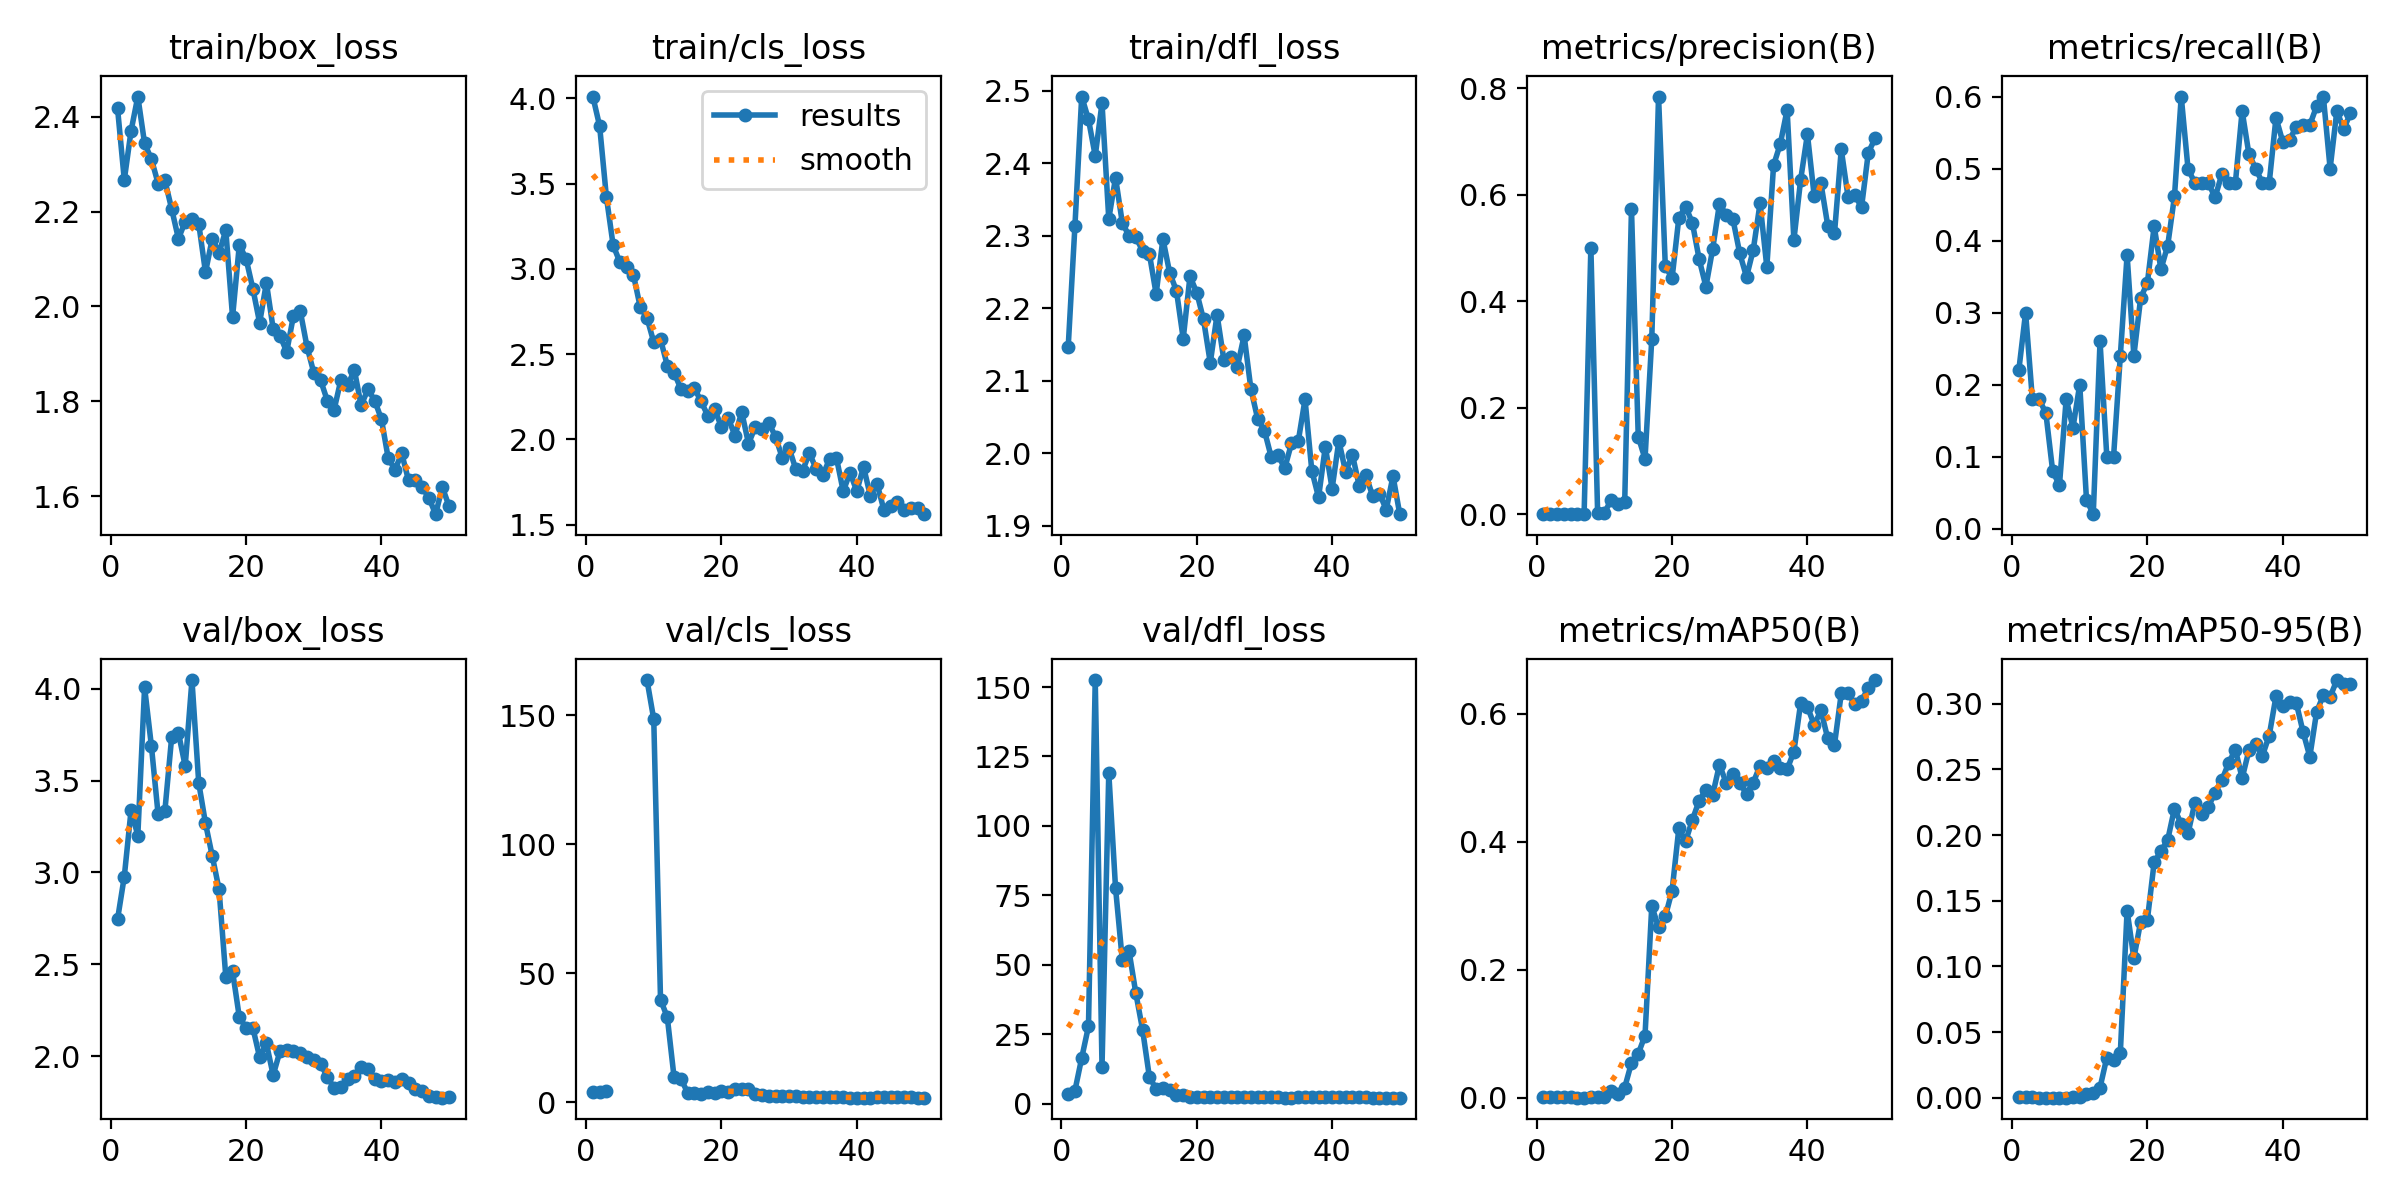

In [ ]:
# Evaluasi & metrik
from IPython.display import Image, display
import os

exp_dir = f"runs/detect/retina_yolov8"

print("Hasil training disimpan di:", exp_dir)

# Tampilkan grafik hasil training
display(Image(filename=os.path.join(exp_dir, "results.png")))

**Confusion Matrix**

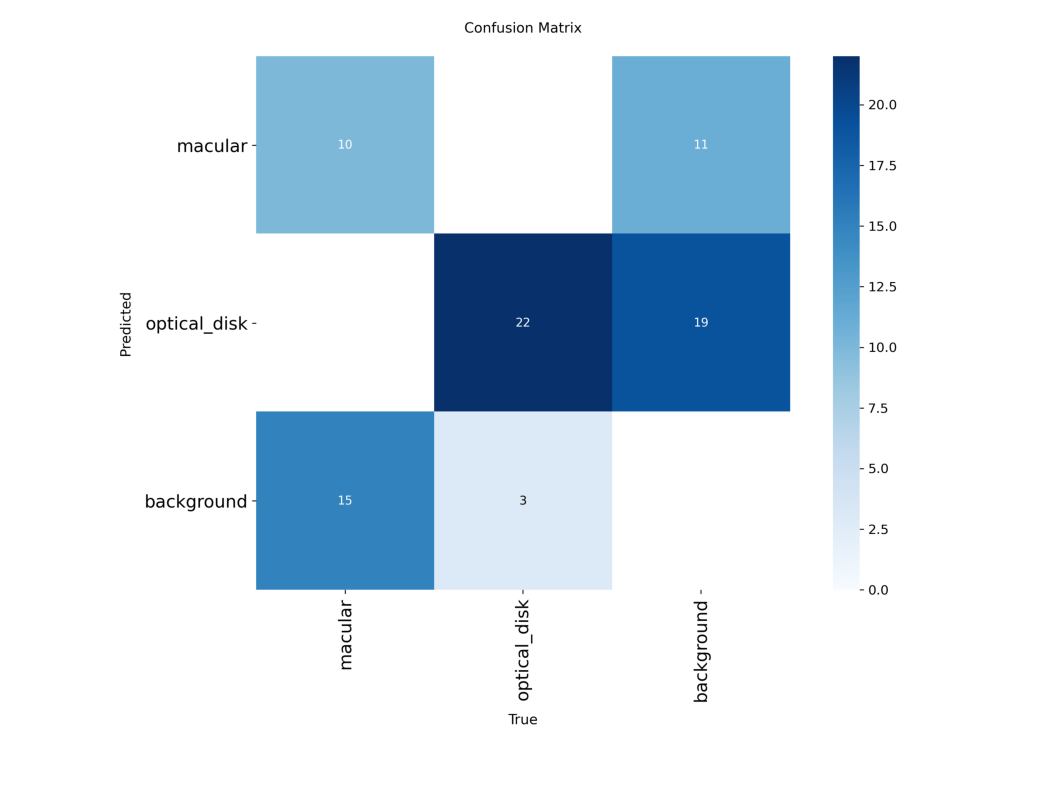

In [ ]:
plt.figure(figsize=(20, 10))
img = cv2.imread(os.path.join(exp_dir, 'confusion_matrix.png'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img, cmap='Blues')
plt.axis("off")
plt.show()

**Menampilkan hasil training (Batch 0)**

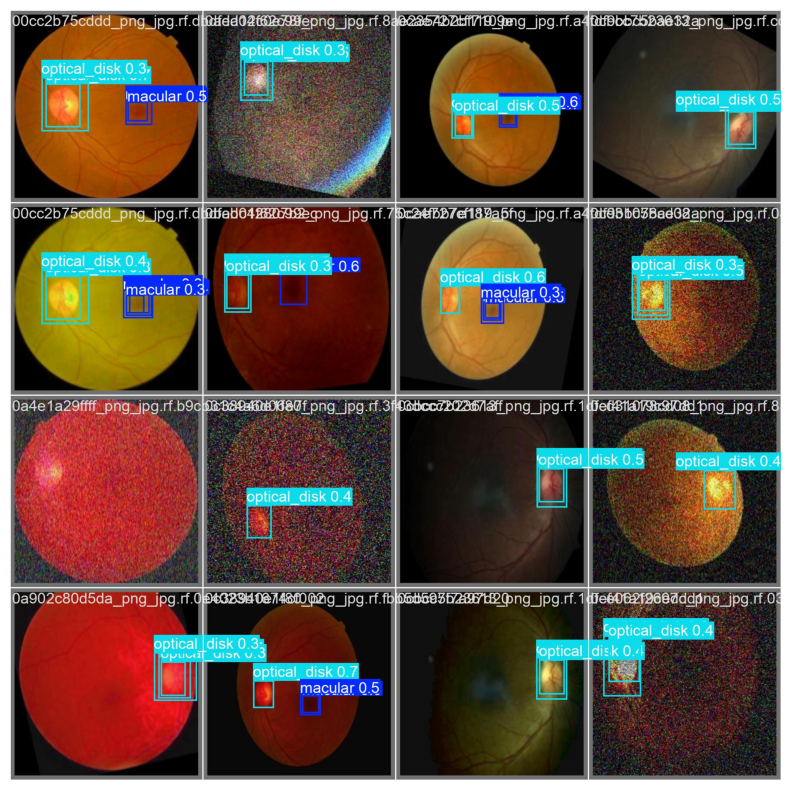

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
img = Image.open(os.path.join(exp_dir, 'val_batch0_pred.jpg'))
plt.imshow(img)
plt.axis('off')
plt.show()

**Menampilkan hasil training (Batch 1)**

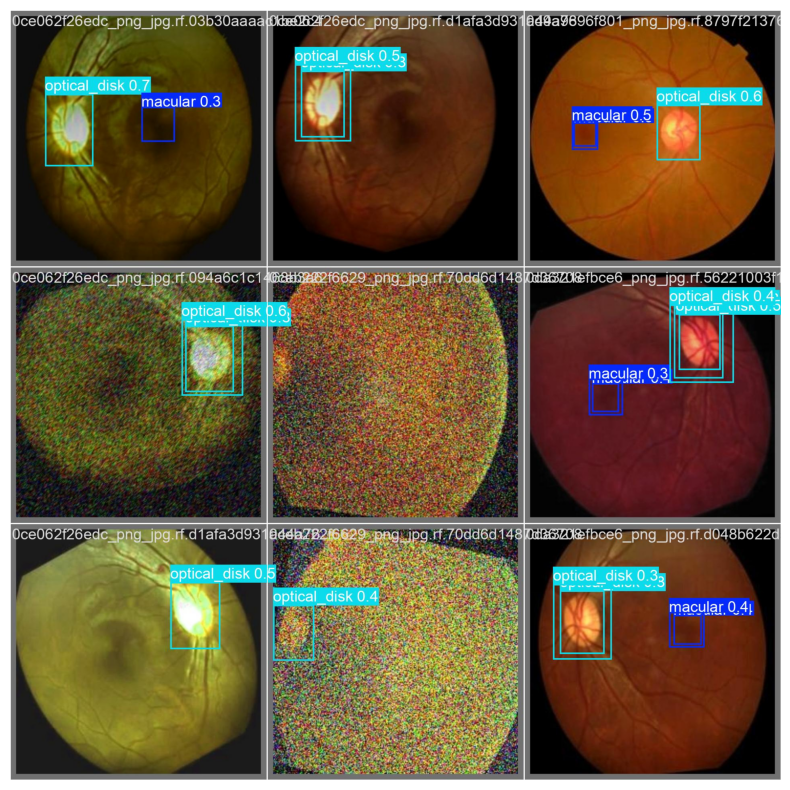

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
img = Image.open(os.path.join(exp_dir, 'val_batch1_pred.jpg'))
plt.imshow(img)
plt.axis('off')
plt.show()